In [42]:
# alpha_prime_calculatorから，完全に移行．

import matplotlib.pyplot as plt
import matplotlib.animation as animation
import matplotlib.patches as patches
import matplotlib.patheffects as path_effects
import matplotlib.patheffects as pe
import matplotlib.patheffects as pe
import numpy as np

def real(z):
    return np.real(z)

def imag(z):
    return np.imag(z)

def abs(z):
    return np.abs(z)

def conj(z):
    return np.conj(z)

def exp(z):
    return np.exp(z)

def log(z):
    return np.log(z)

def sin(z):
    return np.sin(z)

def sqrt(z):
    return np.sqrt(z)

def prod(z):
    return np.prod(z)

def vec_to_map(mm: np.ndarray) -> np.ndarray:
    """MM = [a;c;b;d] (MATLAB TT(:)) -> 2x2 [[a,b],[c,d]]."""
    return np.array([[mm[0], mm[2]], [mm[1], mm[3]]], dtype=np.complex128)

def thz(map_: np.ndarray, z: np.ndarray | complex) -> np.ndarray | complex:
    # az + b / cz + d
    return (map_[0, 0] * z + map_[0, 1]) / (map_[1, 0] * z + map_[1, 1])

def dthz(map_: np.ndarray, z: np.ndarray | complex) -> np.ndarray | complex:
    # derivative of thz
    return 1.0 / (map_[1, 0] * z + map_[1, 1]) ** 2

def build_theta_mlab(qv,dv):
    theta_mlab: dict[int, np.ndarray] = {}
    m = len(qv)
    for k in range(1, m + 1):
        kk = k - 1
        thb = np.array(
            [
                [qv[kk] ** 2 - np.abs(dv[kk]) ** 2, dv[kk]],
                [-np.conj(dv[kk]), 1.0],
            ],
            dtype=np.complex128,
            ) / qv[kk]
        theta_mlab[k] = thb
        theta_mlab[2 * m - (k - 1)] = np.array(
                [[thb[1, 1], -thb[0, 1]], [-thb[1, 0], thb[0, 0]]],
                dtype=np.complex128,
            )
    return theta_mlab


def constmaps_alp(level: int, theta_dict: dict[int, np.ndarray], m: int):
    """[maps, mp, first_idx] = constmaps_alp(level, THETA, M).

    """
    g = 2 * m
    p = np.zeros((4, 2 * m), dtype=np.complex128)
    # p の列配置と同じ添字で「最初に作用した map index」を保持する
    first_applied_map_indices = np.zeros((2 * m,), dtype=int)

    for k in range(1, m + 1):
        tt = theta_dict[k]
        inv_tt = np.array(
            [[tt[1, 1], -tt[0, 1]], [-tt[1, 0], tt[0, 0]]], dtype=np.complex128
        )
        p[:, k - 1] = tt.reshape(-1, order="F").ravel()
        p[:, 2 * m - k] = inv_tt.reshape(-1, order="F").ravel()
        first_applied_map_indices[k - 1] = k
        first_applied_map_indices[2 * m - k] = 2 * m - (k - 1)

    mp_i = np.hstack((np.eye(m), -np.flipud(np.eye(m))))

    for lev in range(2, level + 1):
        a = np.arange(1, g + 1, dtype=int).reshape(-1, 1)
        column: dict[int, np.ndarray] = {}
        for k in range(1, lev + 1):
            col = np.tile(a, (1, g ** (lev - k)))
            col = col.T.ravel()
            col = np.tile(col.reshape(-1, 1), (1, g ** (k - 1)))
            col = col.ravel()
            column[k] = col

        mat = np.asarray(column[1], dtype=int).reshape(-1, 1)
        for k in range(2, lev + 1):
            colk = np.asarray(column[k], dtype=int).reshape(-1, 1)
            mat = np.hstack((colk, mat))

        mp_mat = np.zeros((m, mat.shape[0]), dtype=float)
        for kk in range(1, m + 1):
            mp_mat[kk - 1, :] = np.sum(mat == kk, axis=1) - np.sum(
                mat == (2 * m - (kk - 1)), axis=1
            )

        for l in range(mat.shape[0]):
            map_cand = np.eye(2, dtype=np.complex128)
            for k in range(mat.shape[1]):
                map_cand = map_cand @ theta_dict[mat[l, k]]

            map_vec = map_cand.reshape(-1, order="F").ravel()

            tol = 1e-8
            diff_cols = np.sum(np.abs(p - map_vec[:, None]) > tol, axis=0)
            has_match = np.any(diff_cols == 0)
            id_diff = np.sum(
                np.abs(np.array([1, 0, 0, 1], dtype=np.complex128) - map_vec) > tol
            )
            if (not has_match) and (id_diff != 0):
                p = np.hstack((p, map_vec[:, None]))
                mp_i = np.hstack((mp_i, mp_mat[:, l : l + 1]))
                first_applied_map_indices = np.append(
                    first_applied_map_indices, int(mat[l, 0])
                )

    first_idx = np.asarray(first_applied_map_indices, dtype=int)
    if first_idx.shape[0] != p.shape[1]:
        raise RuntimeError(
            f"first_applied_map_indices length {first_idx.shape[0]} != maps columns {p.shape[1]}"
        )
    return p, mp_i, first_idx



def xhat_inf(z, a, maps):
    l = maps.shape[1]
    xh = np.ones_like(z, dtype=np.complex128)
    for j in range(l):
        map_ = vec_to_map(maps[:, j])
        th_zz = thz(map_, z)
        th_za = thz(map_, a)
        xh = xh * (
            ((th_zz - a) / (th_za - a))
            * ((th_za - z) / (th_zz - z))
        )
    return xh





pi = np.pi
dth = pi / 100
ang_p = np.linspace(-pi, pi, 100)
zp = exp(1j * ang_p)

qv = [0.1,0.1]
dv = [0.4,-0.4]

level = 5
theta_dict = build_theta_mlab(qv, dv)
[maps, mp_i, first_app] = constmaps_alp(level=level, theta_dict=theta_dict, m=len(qv))

print(qv)
print(dv)

def omega(z,a):
    return (z - a) * np.sqrt(xhat_inf(z, a, maps))


[0.1, 0.1]
[0.4, -0.4]


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


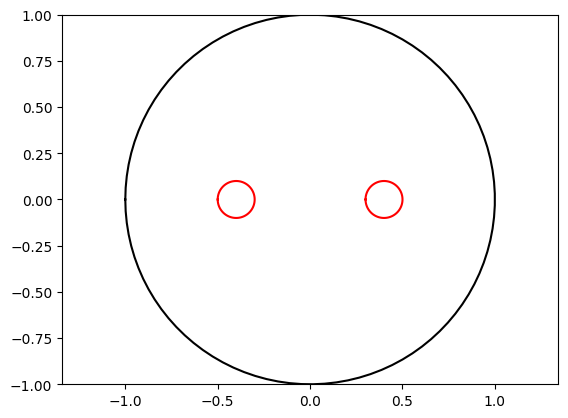

In [43]:
plt.figure()
plt.plot(real(zp),imag(zp),'k-')
for j in range(len(qv)):
    plt.plot(real(zp*qv[j]+dv[j]),imag(zp*qv[j]+dv[j]),'r-')
#plt.savefig("map1.png")
plt.axis('equal')
plt.xlim(-1,1)
plt.ylim(-1,1)
plt.show()
#print(qv)
# seems OK


## Day 4 (Erasmus): three conformal maps — domain vs image (2×3)

| col | domain | map |
|-----|--------|-----|
| (1) | unit disk $\|\zeta\|<1$ | $g=-(\zeta-1)/(\zeta+1)$ |
| (2) | annulus $\rho<\|\zeta\|<1$, $\rho=0.3$ | $g=-P(\zeta,\rho)/P(-\zeta,\rho)$ |
| (3) | multiply connected ($qv$, $dv$) | $g=-\omega(\zeta,1)/\omega(\zeta,-1)$ |

Top row: $\zeta$-plane. Bottom row: image $g(\zeta)$.


In [46]:
RHO_ANN = 0.2
IMAGE_LIM = (-5.0, 5.0)
BND_LW = 3.5
NMAX_P = 40

th_b = np.linspace(-pi, pi, 200, endpoint=False)
z_unit = exp(1j * th_b)
[X, Y] = np.meshgrid(np.linspace(-0.98, 0.98, 22), np.linspace(-0.98, 0.98, 22))


def P_ref(zeta, rho=RHO_ANN, nmax=NMAX_P):
    zeta = np.asarray(zeta, dtype=np.complex128)
    p = 1.0 - zeta
    for n in range(1, nmax + 1):
        p *= (1.0 - rho ** (2 * n) * zeta) * (1.0 - rho ** (2 * n) / zeta)
    return p


def g_mobius(zeta):
    return -(zeta - 1.0) / (zeta + 1.0)


def g_P_ratio(zeta, rho=RHO_ANN):
    return P_ref(zeta, rho) / P_ref(-zeta, rho)


def g_omega_ratio(zeta):
    return -omega(zeta, 1) / omega(zeta, -1)


def _in_disk(xx, yy):
    return xx * xx + yy * yy < 1.0 - 1e-8


def _in_annulus(xx, yy, rho=RHO_ANN):
    r2 = xx * xx + yy * yy
    return r2 > rho * rho + 1e-8 and r2 < 1.0 - 1e-8


def _in_triply(xx, yy):
    if not _in_disk(xx, yy):
        return False
    for j in range(len(qv)):
        if (xx - real(dv[j])) ** 2 + (yy - imag(dv[j])) ** 2 <= qv[j] ** 2 + 1e-10:
            return False
    return True


def _scatter_domain(ax, pred):
    for j in range(len(X)):
        for k in range(len(Y)):
            xx, yy = X[j, k], Y[j, k]
            if pred(xx, yy):
                ax.plot(xx, yy, "k.", markersize=2, alpha=0.45)


def _safe_w(g, z, clip=80.0):
    w = g(z)
    w = np.asarray(w, dtype=np.complex128)
    bad = ~np.isfinite(real(w)) | ~np.isfinite(imag(w)) | (abs(w) > clip)
    w = w.copy()
    w[bad] = np.nan + 1j * np.nan
    return w


def _set_image_square(ax):
    ax.set_xlim(*IMAGE_LIM)
    ax.set_ylim(*IMAGE_LIM)


def plot_panel_disk(ax, *, image=False, g=None, clip=80.0):
    if not image:
        ax.fill(real(z_unit), imag(z_unit), color="white", zorder=0)
        ax.plot(real(z_unit), imag(z_unit), "k-", lw=BND_LW)
        _scatter_domain(ax, _in_disk)
        ax.set_title(r"$|\zeta|<1$", fontsize=10)
        ax.set_xlim(-1.05, 1.05)
        ax.set_ylim(-1.05, 1.05)
    else:
        w = _safe_w(g, z_unit, clip=clip)
        ax.plot(real(w), imag(w), "k-", lw=BND_LW)
        for j in range(len(X)):
            for k in range(len(Y)):
                xx, yy = X[j, k], Y[j, k]
                if not _in_disk(xx, yy):
                    continue
                z = xx + 1j * yy
                if g is g_mobius and abs(z + 1.0) < 0.12:
                    continue
                wpt = _safe_w(g, z, clip=clip)
                if np.isfinite(real(wpt)):
                    ax.plot(real(wpt), imag(wpt), "k.", markersize=2, alpha=0.45)
        ax.set_title(r"$g=-(\zeta-1)/(\zeta+1)$", fontsize=9)
        _set_image_square(ax)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.2)


def plot_panel_annulus(ax, *, image=False, g=None, rho=RHO_ANN, clip=80.0):
    z_out = z_unit
    z_in = rho * z_out
    if not image:
        ax.fill(real(z_out), imag(z_out), color="white", zorder=0)
        ax.fill(real(z_in), imag(z_in), color="white", zorder=1)
        ax.plot(real(z_out), imag(z_out), "k-", lw=BND_LW, label=r"$|\zeta|=1$")
        ax.plot(real(z_in), imag(z_in), color="C1", lw=BND_LW, label=rf"$|\zeta|=\rho$, $\rho={rho}$")
        _scatter_domain(ax, lambda x, y: _in_annulus(x, y, rho))
        ax.set_title(rf"$\rho<|\zeta|<1$, $\rho={rho}$", fontsize=10)
        ax.legend(fontsize=7, loc="upper right")
        ax.set_xlim(-1.05, 1.05)
        ax.set_ylim(-1.05, 1.05)
    else:
        for zb, col in [(z_out, "k"), (z_in, "C1")]:
            w = _safe_w(g, zb, clip=clip)
            ax.plot(real(w), imag(w), color=col, lw=BND_LW)
        for j in range(len(X)):
            for k in range(len(Y)):
                xx, yy = X[j, k], Y[j, k]
                if not _in_annulus(xx, yy, rho):
                    continue
                wpt = _safe_w(g, xx + 1j * yy, clip=clip)
                if np.isfinite(real(wpt)):
                    ax.plot(real(wpt), imag(wpt), "k.", markersize=2, alpha=0.45)
        ax.set_title(rf"$g=-P(\zeta,\rho)/P(-\zeta,\rho)$", fontsize=9)
        _set_image_square(ax)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.2)


def plot_panel_triply(ax, *, image=False, g=None, clip=120.0):
    if not image:
        ax.fill(real(z_unit), imag(z_unit), color="white", zorder=0)
        for j in range(len(qv)):
            zh = z_unit * qv[j] + dv[j]
            ax.fill(real(zh), imag(zh), color="white", zorder=2)
        ax.plot(real(z_unit), imag(z_unit), "k-", lw=BND_LW)
        for j in range(len(qv)):
            zh = z_unit * qv[j] + dv[j]
            ax.plot(real(zh), imag(zh), color=plt.cm.hsv(j / len(qv)), lw=BND_LW)
        _scatter_domain(ax, _in_triply)
        ax.set_title("multiply connected", fontsize=10)
        ax.set_xlim(-1.05, 1.05)
        ax.set_ylim(-1.05, 1.05)
    else:
        w0 = _safe_w(g, z_unit, clip=clip)
        ax.plot(real(w0), imag(w0), "k-", lw=BND_LW)
        for j in range(len(qv)):
            zh = z_unit * qv[j] + dv[j]
            wj = _safe_w(g, zh, clip=clip)
            ax.plot(real(wj), imag(wj), color=plt.cm.hsv(j / len(qv)), lw=BND_LW)
        for j in range(len(X)):
            for k in range(len(Y)):
                xx, yy = X[j, k], Y[j, k]
                if not _in_triply(xx, yy):
                    continue
                wpt = _safe_w(g, xx + 1j * yy, clip=clip)
                if np.isfinite(real(wpt)):
                    ax.plot(real(wpt), imag(wpt), "k.", markersize=2, alpha=0.45)
        ax.set_title(r"$g=-\omega(\zeta,1)/\omega(\zeta,-1)$", fontsize=9)
        _set_image_square(ax)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.2)



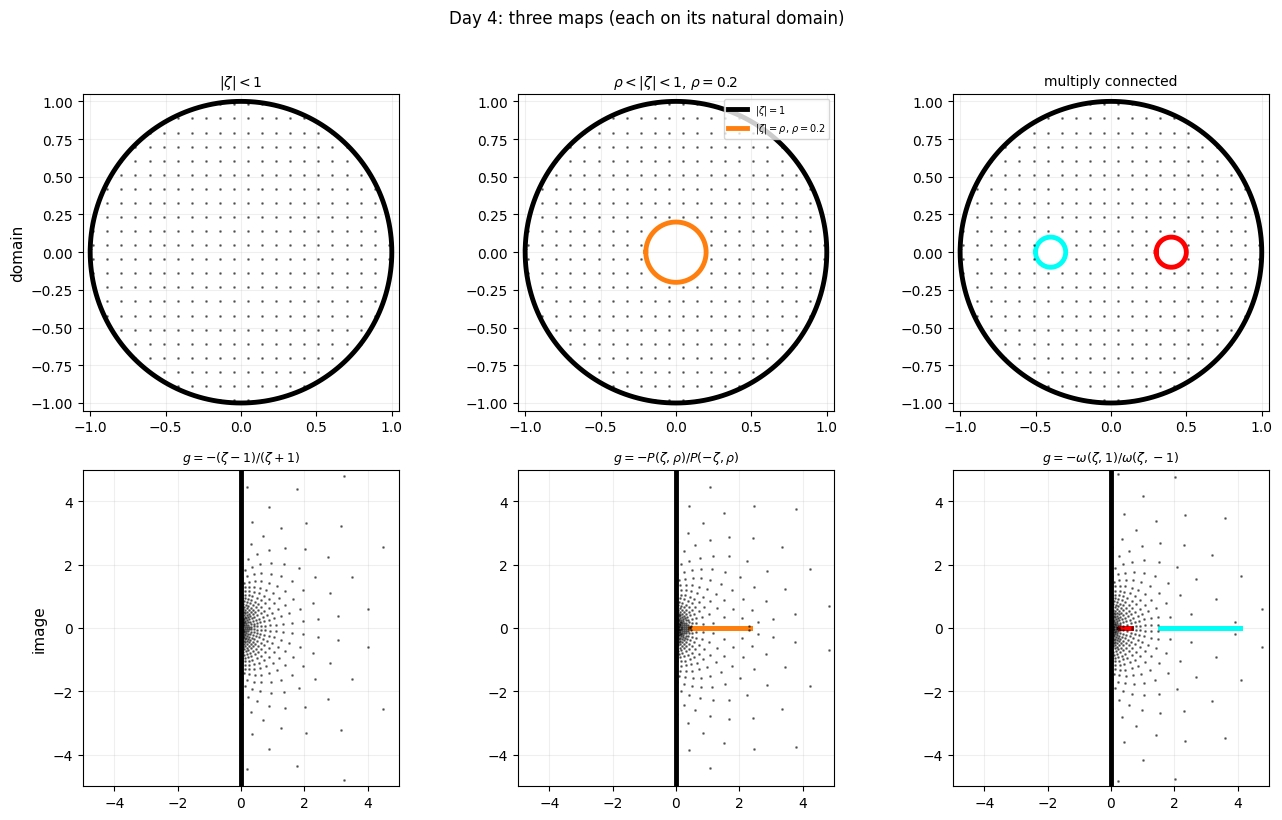

In [47]:
fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.0))

plot_panel_disk(axes[0, 0])
plot_panel_annulus(axes[0, 1], rho=RHO_ANN)
plot_panel_triply(axes[0, 2])

plot_panel_disk(axes[1, 0], image=True, g=g_mobius, clip=80)
plot_panel_annulus(
    axes[1, 1],
    image=True,
    g=lambda z: g_P_ratio(z, rho=RHO_ANN),
    rho=RHO_ANN,
    clip=80,
)
plot_panel_triply(axes[1, 2], image=True, g=g_omega_ratio, clip=120)

axes[0, 0].set_ylabel(r"domain", fontsize=11)
axes[1, 0].set_ylabel(r"image", fontsize=11)
fig.suptitle("Day 4: three maps (each on its natural domain)", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

